---
date: "2026-10-03"
date-modified: last-modified
format:
  html:
    toc: true
---


# Affine Subspaces, Dual Maps, and Matrix Transposition

## 1\. Affine Subspaces (Flats)

A linear [subspace](vector-spaces.ipynb#subspaces) of a [vector space](vector-spaces.ipynb) must contain the zero vector. Translating a linear subspace by a constant vector produces an **affine subspace** (or **flat**, زیرفضای مستوی).

::: {#def-affine-subspace}
## Affine Subspace and Dimension

Let $V$ be a vector space over a [field](field.ipynb) $K$, and let $W \le V$ be a linear subspace. For a fixed vector $a \in V$, the set:

$$E = a + W = \{a + w \mid w \in W\}$$

is called an **affine subspace** (or **flat**) directed by $W$.

The **dimension** of $E$ is defined to be the [dimension](linear-independence-basis-dimension.ipynb#def-dimension) of the underlying linear subspace $W$:

$$\dim(a + W) = \dim W$$
:::

---

### 1.1\. Parallelism of Affine Subspaces

::: {#def-parallel-flats}
## Parallel Affine Subspaces

Let $F = a + F_0$ and $G = b + G_0$ be two affine subspaces of $V$, where $F_0, G_0 \le V$ are linear subspaces. $F$ and $G$ are said to be **parallel** if:

1. One underlying linear subspace is contained in the other: $F_0 \subseteq G_0$ or $G_0 \subseteq F_0$ (in the equal-dimension case, $F_0 = G_0$), and
2. $F \cap G = \emptyset$ (or $F = G$ in the degenerate case).
:::

---

### 1.2\. Intersection of Complementary Affine Subspaces

Consider two affine subspaces in an $n$-dimensional vector space $V$ whose dimensions sum to $n$:

$$E_1 = p + V_1, \qquad E_2 = q + V_2$$

where $V_1, V_2 \le V$ are linear subspaces with $\dim V_1 = k$, $\dim V_2 = l$, and $k + l = n$.

A vector $y \in V$ belongs to the intersection $E_1 \cap E_2$ if and only if there exist $x \in V_1$ and $x' \in V_2$ such that:

$$p + x = q + x' \iff x - x' = q - p \iff q - p \in V_1 + V_2$$

::: {#thm-affine-intersection-stability}
## Intersection Stability of Complementary Affine Subspaces

Let $E_1 = p + V_1$ and $E_2 = q + V_2$ be affine subspaces of an $n$-dimensional vector space $V$ with $\dim E_1 + \dim E_2 = n$.

1. **Single-Point Intersection (Stable):**
   If $E_1 \cap E_2$ consists of a single point, then for **any** parallel translates $E'_1 = p' + V_1$ and $E'_2 = q' + V_2$, the intersection $E'_1 \cap E'_2$ is also **always a single point**.
2. **Higher-Dimensional Intersection (Unstable):**
   If $\dim(E_1 \cap E_2) \ge 1$, then there exists a parallel translate $E'_1 = p' + V_1$ such that:
   $$E'_1 \cap E_2 = \emptyset$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-affine-intersection-stability
By the subspace dimension theorem:

$$\dim(V_1 + V_2) = \dim V_1 + \dim V_2 - \dim(V_1 \cap V_2) = n - \dim(V_1 \cap V_2)$$

**Case 1: $E_1 \cap E_2$ is a single point $\{y_0\}$.**
If $p + x_0 = q + x'_0 = y_0$, then for any other point $y = p + x = q + x' \in E_1 \cap E_2$, we have $(x - x_0) = (x' - x'_0) \in V_1 \cap V_2$. Since the intersection is a single point, the only solution is $x = x_0$ and $x' = x'_0$, which implies $V_1 \cap V_2 = \{0\}$.

Therefore $\dim(V_1 \cap V_2) = 0$, which gives:

$$\dim(V_1 + V_2) = n - 0 = n \implies V_1 + V_2 = V$$

Since $V_1 + V_2 = V$, the space decomposes as a [direct sum](complements-direct-sums-quotient-spaces.ipynb) $V = V_1 \oplus V_2$. For any parallel translates $E'_1 = p' + V_1$ and $E'_2 = q' + V_2$, the difference vector $q' - p'$ lies in $V = V_1 \oplus V_2$, so it has a **unique** decomposition:

$$q' - p' = u - u' \qquad (u \in V_1, u' \in V_2)$$

Thus $p' + u = q' + u'$ is the unique point in $E'_1 \cap E'_2$.

**Case 2: $\dim(E_1 \cap E_2) \ge 1$.**
In this case, $\dim(V_1 \cap V_2) \ge 1$, which implies:

$$\dim(V_1 + V_2) = n - \dim(V_1 \cap V_2) \le n - 1 < n$$

Thus $V_1 + V_2$ is a proper subspace of $V$. Choose any vector $v \notin V_1 + V_2$. Setting $p' = p - v$, the translate $E'_1 = p' + V_1$ satisfies:

$$q - p' = q - p + v$$

If $q - p' \in V_1 + V_2$, then $v = (q - p') - (q - p) \in V_1 + V_2$, contradicting the choice of $v$. Thus $q - p' \notin V_1 + V_2$, which means $E'_1 \cap E_2 = \emptyset$. $\blacksquare$
:::

::: {.callout-note}
## Geometric Interpretation
In $\mathbb{R}^3$, consider a plane ($k = 2$) and a line ($l = 1$), where $k + l = 3$:

- If the line punctures the plane transversely at a single point, any parallel line and plane continue to intersect at a unique point (transverse intersection is structurally stable).
- If the line lies entirely inside the plane (intersection dimension $1$), lifting the line slightly off the plane along a normal direction creates a parallel line that never meets the plane (intersection is empty and unstable).
:::

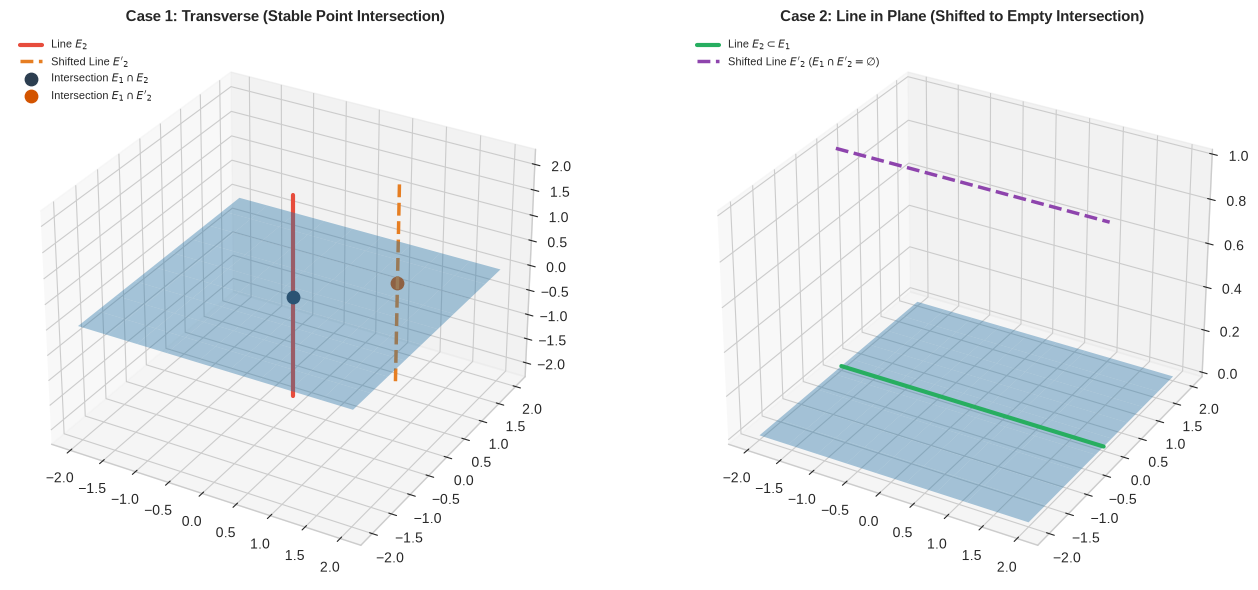

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(14, 6))

# Case 1: Transverse intersection (dim = 0, stable)
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
u = np.linspace(-2, 2, 10)
v = np.linspace(-2, 2, 10)
U, V = np.meshgrid(u, v)
# Plane E_1: z = 0
ax1.plot_surface(U, V, np.zeros_like(U), alpha=0.4, color='#3498db')
# Transverse line E_2: (0, 0, t)
t = np.linspace(-2, 2, 50)
ax1.plot(np.zeros_like(t), np.zeros_like(t), t, color='#e74c3c', lw=3, label='Line $E_2$')
# Parallel translated line E'_2: (1, 1, t)
ax1.plot(np.ones_like(t), np.ones_like(t), t, color='#e67e22', lw=2.5, linestyle='--', label="Shifted Line $E'_2$")
ax1.scatter([0], [0], [0], color='#2c3e50', s=80, label=r'Intersection $E_1 \cap E_2$')
ax1.scatter([1], [1], [0], color='#d35400', s=80, label=r"Intersection $E_1 \cap E'_2$")
ax1.set_title(r'Case 1: Transverse (Stable Point Intersection)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', framealpha=0.9, fontsize=8)

# Case 2: Non-transverse intersection (dim >= 1, unstable)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
# Plane E_1: z = 0
ax2.plot_surface(U, V, np.zeros_like(U), alpha=0.4, color='#3498db')
# Line lying inside plane: (t, 0, 0)
ax2.plot(t, np.zeros_like(t), np.zeros_like(t), color='#27ae60', lw=3, label=r'Line $E_2 \subset E_1$')
# Shifted line off the plane: (t, 0, 1)
ax2.plot(t, np.zeros_like(t), np.ones_like(t), color='#8e44ad', lw=2.5, linestyle='--', label=r"Shifted Line $E'_2$ ($E_1 \cap E'_2 = \emptyset$)")
ax2.set_title(r'Case 2: Line in Plane (Shifted to Empty Intersection)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper left', framealpha=0.9, fontsize=8)

plt.tight_layout()
plt.show()



## 2\. The Dual Map (Transpose / Adjoint Map)

Let $V$ and $W$ be vector spaces over $K$, with [dual spaces](linear-functionals-dual-spaces.ipynb) $V^* = \mathcal{L}(V, K)$ and $W^* = \mathcal{L}(W, K)$.

Every [linear map](linear-maps-and-rank-nullity.ipynb#def-linear-map) $f: V \to W$ induces a canonical linear map in the reverse direction between the dual spaces.

::: {#def-dual-map}
## Dual Map (Transpose Map)

Let $f: V \to W$ be a linear map. The **dual map** (also called the **transpose map** or **adjoint map**, denoted $f^*$ or $f^T$) is the function:

$$f^*: W^* \to V^*$$

defined for each [linear functional](linear-functionals-dual-spaces.ipynb#def-linear-functional) $\alpha \in W^*$ by pullback:

$$f^*(\alpha) = \alpha \circ f$$

That is, for every vector $v \in V$:

$$(f^*(\alpha))(v) = \alpha(f(v))$$
:::

::: {.callout-tip collapse="true"}
## Proof of Linearity of $f^*$
We verify two assertions:

1. **$f^*(\alpha)$ is a linear functional on $V$ (so $f^*(\alpha) \in V^*$):**
   For any $u, v \in V$ and $c \in K$, using linearity of $f$ and $\alpha$:
   $$
   \begin{aligned}
   (f^*(\alpha))(u + v) &= \alpha(f(u + v)) = \alpha(f(u) + f(v)) = \alpha(f(u)) + \alpha(f(v)) = (f^*(\alpha))(u) + (f^*(\alpha))(v) \\
   (f^*(\alpha))(c v) &= \alpha(f(c v)) = \alpha(c f(v)) = c \alpha(f(v)) = c (f^*(\alpha))(v)
   \end{aligned}
   $$
   Thus $f^*(\alpha) \in V^*$.

2. **The map $f^*: W^* \to V^*$ is linear:**
   For any $\alpha, \beta \in W^*$, $c \in K$, and $v \in V$:
   $$
   \begin{aligned}
   (f^*(\alpha + \beta))(v) &= (\alpha + \beta)(f(v)) = \alpha(f(v)) + \beta(f(v)) = (f^*(\alpha))(v) + (f^*(\beta))(v) = (f^*(\alpha) + f^*(\beta))(v) \\
   (f^*(c \alpha))(v) &= (c \alpha)(f(v)) = c \alpha(f(v)) = c (f^*(\alpha))(v) = (c f^*(\alpha))(v)
   \end{aligned}
   $$
   Hence $f^*(\alpha + \beta) = f^*(\alpha) + f^*(\beta)$ and $f^*(c \alpha) = c f^*(\alpha)$. $\blacksquare$
:::

---

### 2.1\. Matrix of the Dual Map is the Transpose

Let $B = (b_1, \dots, b_n)$ be an ordered basis for $V$, and $\bar{B} = (\bar{b}_1, \dots, \bar{b}_m)$ an ordered basis for $W$. Let $B^* = (b^1, \dots, b^n)$ and $\bar{B}^* = (\bar{b}^1, \dots, \bar{b}^m)$ be the respective [dual bases](linear-functionals-dual-spaces.ipynb), satisfying:

$$b^i(b_k) = \delta_{ik}, \qquad \bar{b}^j(\bar{b}_l) = \delta_{jl}$$

::: {#thm-dual-matrix-transpose}
## The Matrix of $f^*$ is the Transpose Matrix $A^T$

Let $A = [f]_B^{\bar{B}} \in M_{m \times n}(K)$ be the [matrix representation](linear-maps-inverses-and-matrices.ipynb#def-matrix-linear-map) of $f$. Then the matrix of $f^*$ with respect to the dual bases $\bar{B}^*$ and $B^*$ is the transpose matrix:

$$[f^*]_{\bar{B}^*}^{B^*} = \left( [f]_B^{\bar{B}} \right)^T = A^T \in M_{n \times m}(K)$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-dual-matrix-transpose
Let $A^* = [f^*]_{\bar{B}^*}^{B^*} = (a^*_{ij}) \in M_{n \times m}(K)$. By definition of the matrix of a linear map, the $j$-th column of $A^*$ consists of the coordinates of $f^*(\bar{b}^j)$ in the dual basis $B^* = (b^1, \dots, b^n)$:

$$f^*(\bar{b}^j) = \sum_{k=1}^n a^*_{kj} b^k$$

Evaluating both sides on the basis vector $b_i \in V$:

$$(f^*(\bar{b}^j))(b_i) = \left( \sum_{k=1}^n a^*_{kj} b^k \right)(b_i) = \sum_{k=1}^n a^*_{kj} \delta_{ki} = a^*_{ij}$$

On the other hand, by definition of the dual map:

$$(f^*(\bar{b}^j))(b_i) = \bar{b}^j(f(b_i))$$

The vector $f(b_i) \in W$ is expressed in the basis $\bar{B} = (\bar{b}_1, \dots, \bar{b}_m)$ using the $i$-th column of $A$:

$$f(b_i) = \sum_{l=1}^m a_{li} \bar{b}_l$$

Applying the dual basis element $\bar{b}^j$:

$$\bar{b}^j(f(b_i)) = \bar{b}^j\left( \sum_{l=1}^m a_{li} \bar{b}_l \right) = \sum_{l=1}^m a_{li} \bar{b}^j(\bar{b}_l) = \sum_{l=1}^m a_{li} \delta_{jl} = a_{ji}$$

Comparing the two expressions:

$$a^*_{ij} = a_{ji}$$

The $(i, j)$-entry of $A^*$ is the $(j, i)$-entry of $A$. Therefore $A^* = A^T$. $\blacksquare$
:::


## 3\. Algebraic Properties of the Dual Map

::: {#thm-dual-composition}
## Dual of a Composition (Reversal of Order)

Let $V_1 \xrightarrow{f} V_2 \xrightarrow{g} V_3$ be linear maps. Then:

$$(g \circ f)^* = f^* \circ g^*$$

In matrix terms, for compatible matrices $A$ and $B$:

$$(B A)^T = A^T B^T$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-dual-composition
Both $(g \circ f)^*$ and $f^* \circ g^*$ map $V_3^* \to V_1^*$. Let $\alpha \in V_3^*$ and $v \in V_1$. By definition of the dual map:

$$
\begin{aligned}
\big( (g \circ f)^*(\alpha) \big)(v) &= \alpha\big( (g \circ f)(v) \big) \\
&= \alpha\big( g(f(v)) \big) \\
&= \big( g^*(\alpha) \big)(f(v)) \\
&= \Big( f^*\big( g^*(\alpha) \big) \Big)(v) \\
&= \big( (f^* \circ g^*)(\alpha) \big)(v)
\end{aligned}
$$

Since this holds for all $v \in V_1$, $(g \circ f)^*(\alpha) = (f^* \circ g^*)(\alpha)$ for all $\alpha \in V_3^*$. Thus $(g \circ f)^* = f^* \circ g^*$.

Taking matrices relative to dual bases, @thm-dual-matrix-transpose immediately gives $(BA)^T = A^T B^T$. $\blacksquare$
:::

---

::: {#cor-dual-invertibility}
## Invertibility and Transposition

Let $f: V \to W$ be an invertible linear map. Then $f^*: W^* \to V^*$ is invertible, and:

$$(f^*)^{-1} = (f^{-1})^*$$

Equivalently, for an invertible square matrix $A$:

$$(A^T)^{-1} = (A^{-1})^T$$
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-dual-invertibility
Since $f \circ f^{-1} = I_W$ and $f^{-1} \circ f = I_V$, applying @thm-dual-composition:

$$(f^{-1})^* \circ f^* = (f \circ f^{-1})^* = I_W^* = I_{W^*}$$
$$f^* \circ (f^{-1})^* = (f^{-1} \circ f)^* = I_V^* = I_{V^*}$$

Thus $(f^{-1})^*$ is the unique two-sided inverse of $f^*$, so $(f^*)^{-1} = (f^{-1})^*$. $\blacksquare$
:::


## 4\. Fundamental Subspaces and Annihilator Relations

Recall that the [annihilator](linear-maps-and-rank-nullity.ipynb#def-annihilator) of a subspace $S \le W$ is $S^\perp = \{\alpha \in W^* \mid \alpha(s) = 0 \;\forall s \in S\}$.

::: {#thm-kernel-dual-annihilator-image}
## Kernel of Dual Map is Annihilator of Image

Let $f: V \to W$ be a linear map. Then:

$$\ker(f^*) = (f(V))^\perp = (\text{im}\, f)^\perp$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-kernel-dual-annihilator-image
Let $\alpha \in W^*$. By definition of kernel:

$$\alpha \in \ker(f^*) \iff f^*(\alpha) = \mathbf{0} \in V^*$$

A functional is zero if and only if it evaluates to zero on all vectors:

$$f^*(\alpha) = \mathbf{0} \iff (f^*(\alpha))(v) = 0 \quad \forall v \in V \iff \alpha(f(v)) = 0 \quad \forall v \in V$$

Since every element of $\text{im}\, f = f(V)$ is of the form $f(v)$ for some $v \in V$, $\alpha(f(v)) = 0$ for all $v \in V$ is precisely the condition that $\alpha$ annihilates $f(V)$:

$$\alpha \in (f(V))^\perp$$

Thus $\ker(f^*) = (f(V))^\perp$. $\blacksquare$
:::

---

### 4.1\. Image of Dual Map and Annihilator of Kernel

Let $\iota_V: V \xrightarrow{\sim} V^{**}$ and $\iota_W: W \xrightarrow{\sim} W^{**}$ denote the canonical [double dual evaluations](linear-functionals-dual-spaces.ipynb#thm-natural-iso) ($\iota(v)(\alpha) = \alpha(v)$).

::: {#lem-double-dual-naturality}
## Naturality Diagram for the Double Dual

For any linear map $f: V \to W$, the following diagram commutes:

$$\iota_W \circ f = f^{**} \circ \iota_V$$
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-double-dual-naturality
Let $v \in V$. We check that $\iota_W(f(v))$ and $f^{**}(\iota_V(v))$ are identical elements of $W^{**}$ by evaluating on any $\beta \in W^*$:

$$\big( \iota_W(f(v)) \big)(\beta) = \beta(f(v))$$

$$\big( f^{**}(\iota_V(v)) \big)(\beta) = \big( \iota_V(v) \circ f^* \big)(\beta) = \iota_V(v)(f^*(\beta)) = (f^*(\beta))(v) = \beta(f(v))$$

Both evaluations yield $\beta(f(v))$. Thus $\iota_W \circ f = f^{**} \circ \iota_V$. $\blacksquare$
:::

::: {#thm-image-dual-annihilator-kernel}
## Image of Dual Map is Annihilator of Kernel

Let $V$ and $W$ be finite-dimensional vector spaces, and let $f: V \to W$ be linear. Under the identification $V^{**} \cong V$:

$$\text{im}(f^*) = (\ker f)^\perp$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-image-dual-annihilator-kernel
Applying @thm-kernel-dual-annihilator-image to the dual map $f^*: W^* \to V^*$:

$$\ker(f^{**}) = \big( \text{im}(f^*) \big)^\perp \le V^{**}$$

Using @lem-double-dual-naturality, $\ker(f^{**}) = \iota_V(\ker f)$. Taking the annihilator of both sides in $V^*$ and using the [double annihilator theorem](linear-maps-and-rank-nullity.ipynb#thm-double-annihilator) $((S^\perp)^\perp = S)$:

$$\text{im}(f^*) = \big( (\text{im}(f^*))^\perp \big)^\perp = (\iota_V(\ker f))^\perp = (\ker f)^\perp$$

$\blacksquare$
:::


## 5\. Equality of Row Rank and Column Rank

For any matrix $A \in M_{m \times n}(K)$:

- The **column rank** of $A$ is the dimension of the subspace of $K^m$ spanned by its columns (the dimension of the image of the corresponding linear map $f$).
- The **row rank** of $A$ is the dimension of the subspace of $K^n$ spanned by its rows (the column rank of $A^T$).

::: {#thm-row-rank-equals-column-rank}
## Row Rank Equals Column Rank

For any matrix $A \in M_{m \times n}(K)$:

$$\text{rank}(A^T) = \text{rank}(A)$$

That is, the row rank of $A$ is always equal to its column rank.
:::

::: {.callout-tip collapse="true"}
## Coordinate-Free Proof via Duality
Let $f: V \to W$ be the linear map represented by $A$, where $\dim V = n$ and $\dim W = m$. Then $A^T$ represents the dual map $f^*: W^* \to V^*$.

1. **Rank of $f^*$:** By the [rank-nullity theorem](linear-maps-and-rank-nullity.ipynb#thm-rank-nullity) applied to $f^*: W^* \to V^*$:
   $$\text{rank}(f^*) = \dim(f^*(W^*)) = \dim W^* - \dim(\ker f^*)$$

2. **Dimension of $\ker(f^*)$:** By @thm-kernel-dual-annihilator-image, $\ker(f^*) = (f(V))^\perp$. By the [annihilator dimension formula](linear-maps-and-rank-nullity.ipynb#cor-annihilator-dim):
   $$\dim(\ker f^*) = \dim\big((f(V))^\perp\big) = \dim W - \dim(f(V)) = m - \text{rank}(f)$$

3. **Equating ranks:** Since $\dim W^* = \dim W = m$, substitute $\dim(\ker f^*)$ into the rank formula:
   $$
   \begin{aligned}
   \text{rank}(f^*) &= m - \big( m - \text{rank}(f) \big) \\
   &= \text{rank}(f)
   \end{aligned}
   $$

Since $\text{rank}(f^*) = \text{rank}(A^T)$ and $\text{rank}(f) = \text{rank}(A)$, we conclude:

$$\text{rank}(A^T) = \text{rank}(A)$$

$\blacksquare$
:::

::: {.callout-note}
## Significance of the Duality Proof
Traditional elementary proofs of row rank = column rank rely on Gaussian elimination or inner products. The proof above demonstrates that equality of row and column rank is an intrinsic, coordinate-free consequence of duality and the rank-nullity theorem, requiring no metric or inner product structure.
:::

---

### 5.1\. Row-Column Duality Perspective

- Vectors $v \in K^n$ are canonically represented as **column vectors** ($n \times 1$).
- Linear functionals $\alpha \in (K^n)^*$ are canonically represented as **row vectors** ($1 \times n$).
- The evaluation pairing $\alpha(v)$ is matrix multiplication of a row by a column:

$$\begin{pmatrix} y_1 & y_2 & \dots & y_n \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{pmatrix} = \sum_{i=1}^n y_i x_i$$

- The standard dual basis vectors correspond to the elementary row vectors $e^i = (0, \dots, 1, \dots, 0)$. Transposition interconverts column representations and row representations, embodying the duality between $V$ and $V^*$.

In [2]:

import numpy as np

# 1. Define a 3x4 matrix A (representing f: R^4 -> R^3)
A = np.array([
    [1.0,  2.0,  0.0, -1.0],
    [2.0,  4.0,  1.0,  1.0],
    [1.0,  2.0,  1.0,  2.0]
])
m, n = A.shape

# Note: Row 3 = Row 2 - Row 1, so rank must be 2
col_rank = np.linalg.matrix_rank(A)
row_rank = np.linalg.matrix_rank(A.T)

print("=== Matrix A (3x4) ===\n", A)
print("Column Rank of A:", col_rank)
print("Row Rank of A (Rank of A^T):", row_rank)
print("Row Rank == Column Rank:", col_rank == row_rank)

# 2. Verify ker(f^*) = (im(f))^perp
# A vector y in R^3 is in (im(f))^perp iff y^T A = 0 iff A^T y = 0
# Find null space of A^T
U, S, Vt = np.linalg.svd(A.T)
null_mask = S < 1e-10
null_dim = A.T.shape[1] - np.sum(~null_mask)
null_basis_AT = Vt[-null_dim:].T

print("\n=== Verification of ker(f^*) = (im f)^perp ===")
print("Basis for ker(A^T) [Annihilator of im(A)]:\n", np.round(null_basis_AT, 4))
print("Check A^T @ null_vector == 0:", np.allclose(A.T @ null_basis_AT, 0))
print("Dimension check: dim ker(f^*) =", null_basis_AT.shape[1])
print("m - rank(A) = 3 - 2 =", m - col_rank)

# 3. Verify (BA)^T = A^T B^T
B = np.array([
    [2.0, -1.0,  3.0],
    [0.0,  1.0, -2.0]
])
BA = B @ A
print("\n=== Product Transpose Identity (BA)^T = A^T B^T ===")
print("(BA)^T == A^T @ B^T:", np.allclose(BA.T, A.T @ B.T))


=== Matrix A (3x4) ===
 [[ 1.  2.  0. -1.]
 [ 2.  4.  1.  1.]
 [ 1.  2.  1.  2.]]
Column Rank of A: 2
Row Rank of A (Rank of A^T): 2
Row Rank == Column Rank: True

=== Verification of ker(f^*) = (im f)^perp ===
Basis for ker(A^T) [Annihilator of im(A)]:
 [[-0.5774]
 [ 0.5774]
 [-0.5774]]
Check A^T @ null_vector == 0: True
Dimension check: dim ker(f^*) = 1
m - rank(A) = 3 - 2 = 1

=== Product Transpose Identity (BA)^T = A^T B^T ===
(BA)^T == A^T @ B^T: True
